# Hypergamic Matching Markets

Hypergamy is the norm that a partner should not rank below oneself on the traits a
society treats as competitive — status first, then attractiveness. Formally it is not a
preference for richer men; it is an *asymmetric* preference, an indicator that fires for
one side and not the other. A market where only one side discounts downward has a
systematically different equilibrium from one where both sides do.

Insert a recommender between the two sides and the mechanism changes twice over. The
algorithm decides who sees whom, so it sets the composition of everyone's choice set;
and because it learns from engagement, the exposure it hands out becomes the data it
learns from next epoch. Concentration is not just a display choice — it is the training
signal. This notebook runs one small population through that loop and asks what the
market does to itself: how concentrated exposure becomes, what the mediation costs
against a full-information benchmark, and whether the hypergamy parameter itself moves
the result.

Everything below runs on N = 500 agents for 50 epochs, in well under three minutes. That
is a demonstration size, not an experimental one: the committed tables in
`data/processed/` use N = 1000, five seeds and a 20-epoch horizon, and the committed
config file ships a 100-epoch schedule. The numbers here are a single seed at half that
population and will not reproduce those tables.


In [1]:
# sys.path first, before any project import. Both directories are found by walking up
# from the working directory until the repo root is in sight, so the notebook runs the
# same whether the kernel starts in notebooks/, in the repo root, or in a subdirectory.
import pathlib
import sys

REPO = pathlib.Path.cwd().resolve()
while not (REPO / "src" / "python" / "orchestrator.py").is_file():
    if REPO.parent == REPO:
        raise RuntimeError(
            "could not find the repo root above the working directory; start the "
            "kernel somewhere inside the checkout"
        )
    REPO = REPO.parent

for path in (REPO, REPO / "build" / "Release"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import copy
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, display
from tqdm.auto import tqdm

with open(REPO / "experiments" / "base.yaml", encoding="utf-8") as fh:
    base_config = yaml.safe_load(fh)

# 500 agents, not the config's 1000: this notebook is a demonstration and the binding
# constraint is wall-clock. The file on disk is untouched; only this in-memory copy is
# resized, and every Simulation below is constructed from a deepcopy of it.
base_config["population"]["n"] = 500

# The orchestrator logs one INFO line per epoch. Across the main run and five sweep
# arms that is several hundred lines of stdout in a notebook whose point is the figures.
logging.getLogger("src.python.orchestrator").setLevel(logging.WARNING)

from src.python import figures  # noqa: E402
from src.python.attribution import delta_power  # noqa: E402
from src.python.config import InertGateWarning  # noqa: E402
from src.python.figures import FIGURES  # noqa: E402
from src.python.metrics import gini  # noqa: E402
from src.python.orchestrator import Simulation  # noqa: E402
from _hypergamic import sample_population  # noqa: E402

# Draw the ad-hoc cells in the same style as the saved figures, so the notebook's
# inline charts and the PNGs beside them are one visual system rather than two.
figures.apply_style()

# Which interpreter is running this is part of the result: the simulator's numbers
# depend on the pinned torch and numpy (requirements.txt), and a different stack gives
# slightly different trajectories from the same seed. Printed rather than assumed, so a
# notebook run on the wrong kernel is visible in its own output.
import numpy
import torch

print(f"python    {sys.version.split()[0]}  ({sys.executable})")
print(f"numpy     {numpy.__version__}   torch {torch.__version__}")
FIGURES.mkdir(parents=True, exist_ok=True)
print(f"repo      {REPO}")
print(f"figures   {FIGURES}")
print(f"N         {base_config['population']['n']}")
print(f"seed      {base_config['population']['seed']}")
print(f"delta     {base_config['hypergamy']['delta']}")


python    3.12.10  (D:\hypergamic-matching-markets\.venv\Scripts\python.exe)
numpy     1.26.4   torch 2.3.1+cpu
repo      D:\hypergamic-matching-markets
figures   D:\hypergamic-matching-markets\docs\figures
N         500
seed      42
delta     0.5


## Where the population starts

Four traits are drawn independently from the distributions in `experiments/base.yaml`.
None of them is a measured quantity — they are modelling constructs with no units, and
THEORY.md §1.1 is explicit that they must not be compared to real data. What matters
for the mechanism is only their *rank order*: the utility z-scores each trait against
the population before weighting it, so a monotone rescaling of any column would leave
every number in this notebook unchanged.

The split is M (proposers, column 1 = 0) against W (acceptors, column 1 = 1), roughly
half the population each. The hypergamy indicator will read W's status against M's, so
the two panels that matter most are the first row.

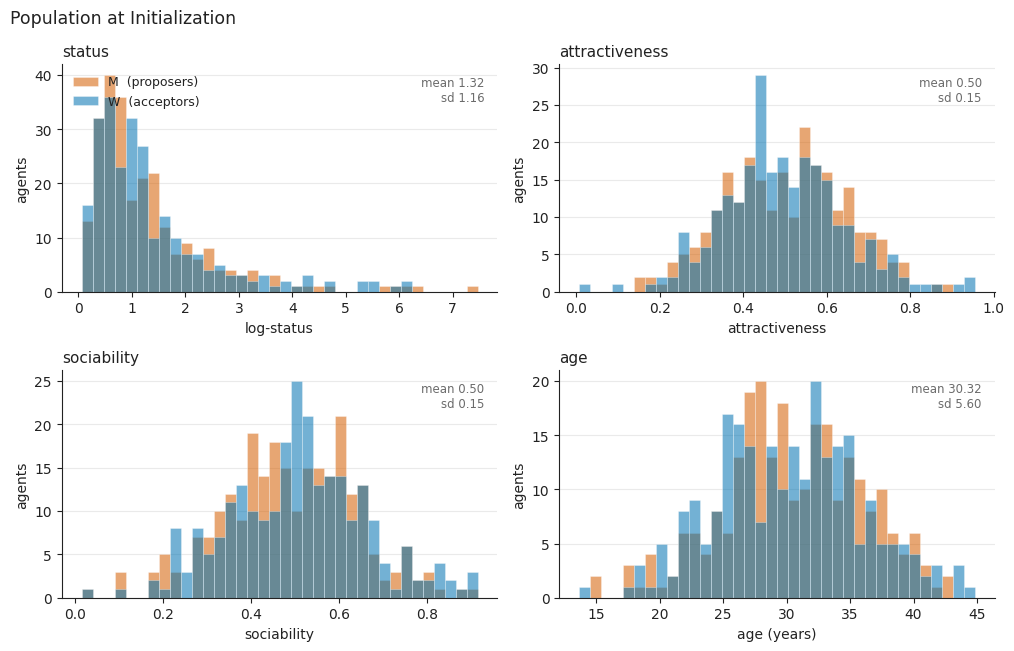

status is lognormal, so its raw scale is skewed: median 0.96, max 7.47
attractiveness and sociability are clipped to [0, 1] at sampling: 0.01-0.96, 0.02-0.91


In [2]:
states = sample_population(int(base_config["population"]["n"]), base_config,
                           int(base_config["population"]["seed"]))

TRAITS = [
    (2, "status", "log-status"),
    (3, "attractiveness", "attractiveness"),
    (4, "sociability", "sociability"),
    (5, "age", "age (years)"),
]
SIDES = [(0.0, "M  (proposers)", figures.VERMILLION), (1.0, "W  (acceptors)", figures.BLUE)]

fig, axes = plt.subplots(2, 2, figsize=(10.2, 6.6))
for ax, (col, name, xlabel) in zip(axes.ravel(), TRAITS):
    values = states[:, col]
    # One shared bin edge set across both groups, so the two histograms are
    # comparable rather than each scaled to its own range.
    edges = np.histogram_bin_edges(values, bins=36)
    for side, label, colour in SIDES:
        ax.hist(values[states[:, 1] == side], bins=edges, color=colour, alpha=0.55,
                label=label, edgecolor="white", linewidth=0.4)
    ax.set_title(name, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("agents")
    ax.grid(axis="x", visible=False)
    ax.annotate(f"mean {values.mean():.2f}\nsd {values.std(ddof=1):.2f}",
                xy=(0.97, 0.95), xycoords="axes fraction", ha="right", va="top",
                fontsize=8.5, color=figures.GREY)

axes[0, 0].legend(loc="upper left", fontsize=9)
fig.suptitle("Population at Initialization", x=0.01, ha="left", fontsize=12.5)
fig.tight_layout()
fig.savefig(FIGURES / "population.png", dpi=150, bbox_inches="tight",
            facecolor="white")
plt.show()

print(f"status is lognormal, so its raw scale is skewed: "
      f"median {np.median(states[:, 2]):.2f}, max {states[:, 2].max():.2f}")
print(f"attractiveness and sociability are clipped to [0, 1] at sampling: "
      f"{states[:, 3].min():.2f}-{states[:, 3].max():.2f}, "
      f"{states[:, 4].min():.2f}-{states[:, 4].max():.2f}")

## Running the market

Each epoch is one pass through the pipeline in `orchestrator.py`: generate a swipe log,
train the recommender on it, take each agent's top-k shortlist from the trained model,
run deferred acceptance on those lists, score the matching, and move each agent's
selectivity θ toward whatever yield she just got. Stage six is what makes this a
simulation rather than a repeated experiment — the market's own history changes what it
does next.

The loop runs here one epoch at a time so the progress bar tracks real work. That is not
a cosmetic choice: `run()` keys everything on the absolute epoch index, so 50 calls of
`run(1, start_epoch=e)` reproduce a single `run(50)` bit for bit — same exposure matrix,
same Gini series, same Pareto fit. The cell asserts it at the end rather than claiming it.

In [3]:
N_EPOCHS = 50
N_AGENTS = int(base_config["population"]["n"])

sim = Simulation(config=copy.deepcopy(base_config), recommender="ncf")

chunks, exposures = [], []
for epoch in tqdm(range(N_EPOCHS), desc="epochs", unit="ep"):
    chunks.append(sim.run(1, start_epoch=epoch))
    exposures.append(sim.exposure_series.copy())

metrics_df = pd.concat(chunks, ignore_index=True)
exposure_series = np.concatenate(exposures)

# The claim in the markdown above, checked rather than asserted in prose.
whole = Simulation(config=copy.deepcopy(base_config), recommender="ncf").run(N_EPOCHS)
assert np.allclose(metrics_df["gini"].to_numpy(), whole["gini"].to_numpy(), rtol=0, atol=0)
assert np.allclose(metrics_df["welfare_total"].to_numpy(),
                   whole["welfare_total"].to_numpy(), rtol=0, atol=0)
del whole

print(f"{len(metrics_df)} epochs, arm={metrics_df['arm'].iloc[0]}, "
      f"{float(metrics_df['mean_swipes_per_agent'].iloc[-1]):.0f} swipes per agent per epoch")
metrics_df.tail()

epochs:   0%|          | 0/50 [00:00<?, ?ep/s]

50 epochs, arm=ncf, 97 swipes per agent per epoch


,epoch,generation,delta,seed,gini,mcr,rsi,bpr,welfare_alg,welfare_full,...,top1_share,mean_proposal_intent,separating_threshold,proposal_cost_total,value_created,defection_loss,welfare_total,welfare_common,welfare_selected,welfare_selection_artifact
45,45,2,0.5,42,0.852950,0.144,0.438889,1320.444444,358.822298,2170.27732,...,0.1201,0.511040,0.0,0.0,169.048061,13.390425,155.657637,NaN,NaN,NaN
46,46,2,0.5,42,0.847846,0.152,0.452632,1230.789474,370.755779,2170.27732,...,0.1193,0.511877,0.0,0.0,173.592768,15.160095,158.432672,NaN,NaN,NaN
47,47,2,0.5,42,0.846330,0.152,0.423684,1226.447368,381.443149,2170.27732,...,0.1196,0.512037,0.0,0.0,179.265884,14.145472,165.120413,NaN,NaN,NaN
48,48,2,0.5,42,0.835981,0.152,0.443421,1229.921053,378.622168,2170.27732,...,0.1182,0.512169,0.0,0.0,173.682375,15.959355,157.723020,NaN,NaN,NaN
49,49,2,0.5,42,0.837824,0.152,0.426316,1228.868421,388.973263,2170.27732,...,0.1194,0.512729,0.0,0.0,173.616584,14.023266,159.593318,NaN,NaN,NaN


wrote D:\hypergamic-matching-markets\docs\figures\dashboard.png


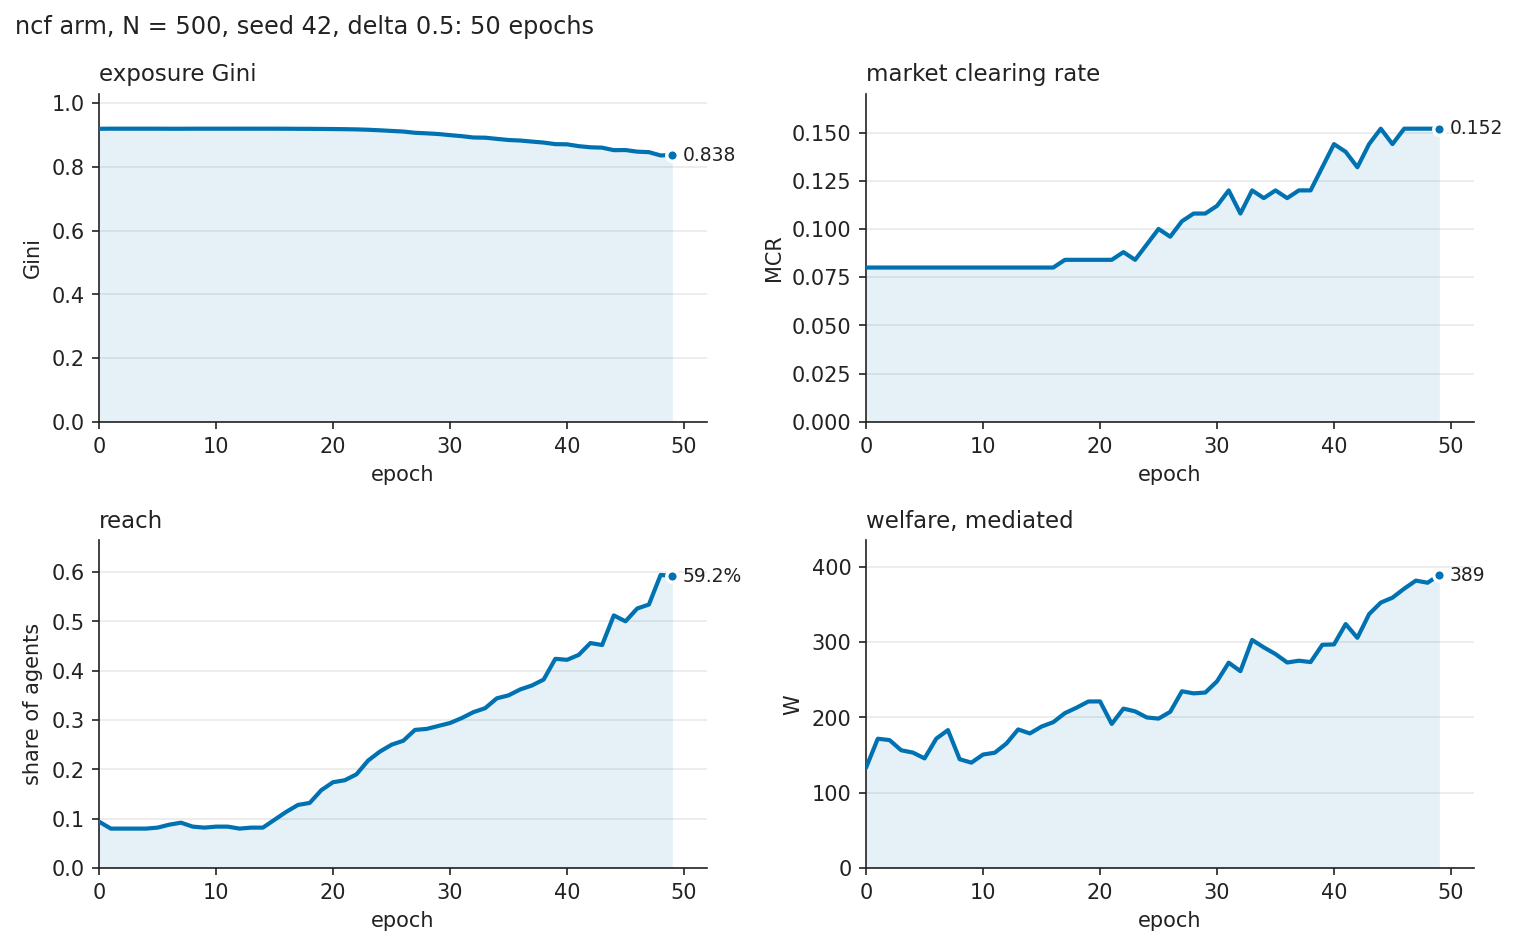

welfare at epoch 50: mediated 389.0 against a full-information benchmark of 2170.3
algorithmic loss 0.821; clearing rate 0.152


In [4]:
fig = figures.save_dashboard(metrics_df, n_agents=N_AGENTS)
print(f"wrote {FIGURES / 'dashboard.png'}")

# save_dashboard returns a matplotlib.figure.Figure built directly rather than through
# pyplot, so it is outside pyplot's registry and plt.show() cannot display it. Rather
# than reimplement the panels here, the saved PNG is displayed: that guarantees the
# inline image is byte-identical to the file the README embeds, which is the property
# that matters. dpi=150 and bbox_inches='tight' were already applied by save_dashboard.
display(Image(filename=str(FIGURES / "dashboard.png")))

print(f"welfare at epoch {N_EPOCHS}: mediated {metrics_df['welfare_alg'].iloc[-1]:.1f} "
      f"against a full-information benchmark of {metrics_df['welfare_full'].iloc[-1]:.1f}")
print(f"algorithmic loss {metrics_df['algorithmic_loss'].iloc[-1]:.3f}; "
      f"clearing rate {metrics_df['mcr'].iloc[-1]:.3f}")


## The Matthew effect, as a shape

The Gini in the dashboard is one number per epoch. A Lorenz curve shows the same
inequality as a shape, which is what makes it readable: the curve plots the cumulative
share of exposure held by the least-exposed agents first, so a curve sagging toward the
bottom-right corner means a large share of agents accounts for a small share of
visibility.

This is the headline figure. It compares **epoch 1 against epoch 50 of the same run and
the same population**: what changed is exposure, not who the agents are. Both Gini values
are labelled on the axes because the number is what a reader will quote.

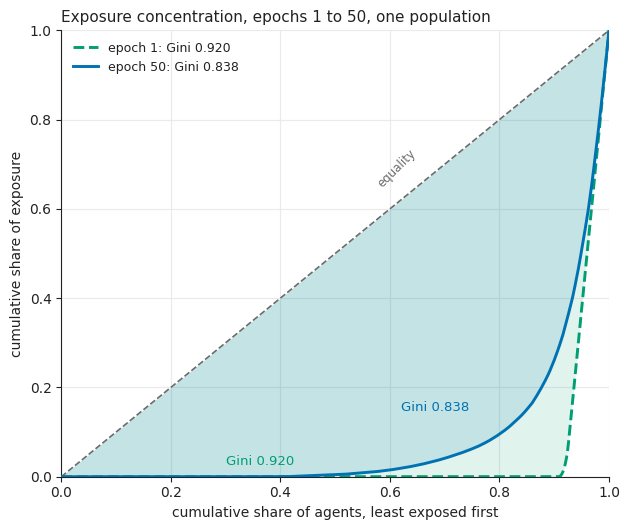

Gini 0.920 -> 0.838; reach 9.4% -> 59.2%
top 1% of agents hold 12.5% of exposure at epoch 1, 11.9% at epoch 50


In [5]:
first, last = 0, N_EPOCHS - 1  # the frame is 0-indexed: row 0 is epoch 1

g_first = gini(exposure_series[first])
g_last = gini(exposure_series[last])

# plot_lorenz is the primitive the committed matthew_effect figure draws: two exposure
# vectors, the equality diagonal, a Gini per curve. Drawn into pyplot-owned axes here
# rather than into a bare Figure, because only a pyplot axis renders inline.
fig_lor, ax_lor = plt.subplots(figsize=(6.4, 5.4))
figures.plot_lorenz(exposure_series[first], exposure_series[last], ax=ax_lor)

handles, _ = ax_lor.get_legend_handles_labels()
ax_lor.legend(handles, [f"epoch {first + 1}: Gini {g_first:.3f}",
                        f"epoch {last + 1}: Gini {g_last:.3f}"],
              loc="upper left", fontsize=9)

# Labelled on the curves as well as in the legend: this is the figure a reader
# screenshots, and the legend is the part a screenshot loses.
ax_lor.annotate(f"Gini {g_first:.3f}", xy=(0.30, 0.02), fontsize=9.5,
                color=figures.GREEN, ha="left", va="bottom")
ax_lor.annotate(f"Gini {g_last:.3f}", xy=(0.62, 0.14), fontsize=9.5,
                color=figures.BLUE, ha="left", va="bottom")
ax_lor.set_title(f"Exposure concentration, epochs {first + 1} to {last + 1}, "
                 f"one population", loc="left")

fig_lor.tight_layout()
fig_lor.savefig(FIGURES / "matthew.png", dpi=150, bbox_inches="tight",
                facecolor="white")
plt.show()

print(f"Gini {g_first:.3f} -> {g_last:.3f}; "
      f"reach {metrics_df['reach'].iloc[first]:.1%} -> {metrics_df['reach'].iloc[last]:.1%}")
print(f"top 1% of agents hold {metrics_df['top1_share'].iloc[first]:.1%} of exposure at "
      f"epoch {first + 1}, {metrics_df['top1_share'].iloc[last]:.1%} at epoch {last + 1}")


## Does hypergamy itself change the curve?

δ is the status surplus W requires: the indicator fires when a candidate's status sits
at least δ population standard deviations above her own. δ = 0 is the no-hypergamy
baseline — every candidate is admissible on status — and larger δ is a stricter norm.

Each of the five arms is a fresh `Simulation` on the same seed, so the population, the
seed and the weights are identical and only δ moves. The faint line at δ = 0 is the
baseline the other four are read against.

delta sweep:   0%|          | 0/5 [00:00<?, ?arm/s]

delta-inert warnings: 0


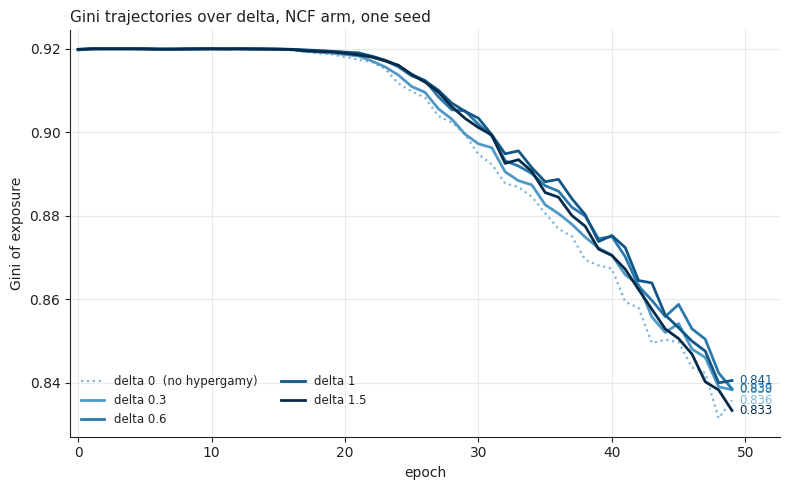

       gini_first  gini_last  mcr_last  rsi_last  shortlist_overlap_vs_delta0
delta                                                                        
0.0        0.9198     0.8358     0.156    0.4769                       1.0000
0.3        0.9199     0.8383     0.156    0.4885                       0.9364
0.6        0.9198     0.8385     0.164    0.5110                       0.8902
1.0        0.9197     0.8405     0.180    0.5411                       0.8596
1.5        0.9199     0.8334     0.164    0.4890                       0.8528


In [6]:
DELTAS = [0.0, 0.3, 0.6, 1.0, 1.5]
# One hue, light to dark, because delta is an ordered quantity and a categorical
# palette would throw that ordering away. Validated as an ordinal ramp: monotone
# lightness, every step gap visible, the light end clears the surface.
RAMP = ["#7FB5D6", "#5099C6", "#2A79AC", "#125686", "#062B4A"]

trajectories: dict[float, pd.DataFrame] = {}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    for delta in tqdm(DELTAS, desc="delta sweep", unit="arm"):
        cfg = copy.deepcopy(base_config)
        cfg["hypergamy"]["delta"] = delta
        run = Simulation(config=cfg, recommender="ncf")
        trajectories[delta] = run.run(N_EPOCHS)

# The library warns when delta cannot bind at all (THEORY.md §2.2). Report it if it
# fires: a flat sweep line means one of two very different things, and this is what
# tells them apart.
inert = [w for w in caught if issubclass(w.category, InertGateWarning)]
print(f"delta-inert warnings: {len(inert)}")

population = sample_population(N_AGENTS, base_config, int(base_config["population"]["seed"]))
overlap = {d: delta_power(population, {**base_config, "hypergamy": {
    **base_config["hypergamy"], "delta": d}}, deltas=(0.0, d), k=20)
    if d > 0 else 1.0 for d in DELTAS}

fig = plt.figure(figsize=(8.0, 5.0), facecolor="white")
ax = fig.add_subplot(111)
for delta, colour in zip(DELTAS, RAMP):
    frame = trajectories[delta]
    is_baseline = delta == 0.0
    ax.plot(frame["epoch"], frame["gini"], color=colour,
            lw=1.6 if is_baseline else 2.0, ls=":" if is_baseline else "-",
            label=f"delta {delta:g}" + ("  (no hypergamy)" if is_baseline else ""),
            zorder=3 if not is_baseline else 2)
    ax.annotate(f"{frame['gini'].iloc[-1]:.3f}",
                xy=(frame["epoch"].iloc[-1], frame["gini"].iloc[-1]),
                xytext=(5, 0), textcoords="offset points", va="center",
                fontsize=8.5, color=colour)

ax.set_xlabel("epoch")
ax.set_ylabel("Gini of exposure")
ax.set_xlim(-0.6, N_EPOCHS + 2.6)
ax.set_title("Gini trajectories over delta, NCF arm, one seed", loc="left")
ax.legend(loc="lower left", fontsize=8.5, ncol=2)
fig.tight_layout()
fig.savefig(FIGURES / "sweep.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

summary = pd.DataFrame({
    "delta": DELTAS,
    "gini_first": [trajectories[d]["gini"].iloc[0] for d in DELTAS],
    "gini_last": [trajectories[d]["gini"].iloc[-1] for d in DELTAS],
    "mcr_last": [trajectories[d]["mcr"].iloc[-1] for d in DELTAS],
    "rsi_last": [trajectories[d]["rsi"].iloc[-1] for d in DELTAS],
    "shortlist_overlap_vs_delta0": [overlap[d] for d in DELTAS],
}).set_index("delta")
print(summary.round(4).to_string())

## Generations and the Pareto tail

At each generation boundary the bottom fifth of agents by cumulative match count is
replaced with a fresh draw from the same distributions: newcomers get new traits, new
chemistry keys and a θ recalibrated against the market they actually enter. Survivors
keep everything, including the θ they earned.

The Pareto α fitted on cumulative match counts is a tail index for how unequal the
total match history is: smaller α means a heavier tail, with a few agents holding most
of the matches. It is fitted only on each generation's final row, because a fit on a
partial generation would be a number about the middle of a process.

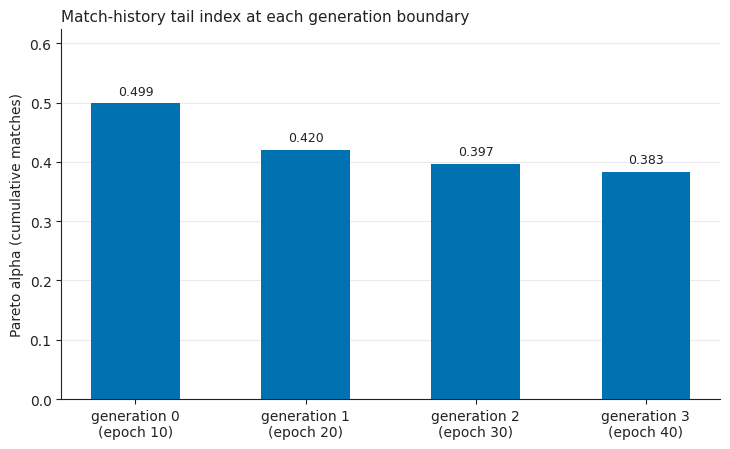

 epoch  generation  pareto_alpha     gini   mcr
     9           0      0.498730 0.919998 0.080
    19           1      0.420091 0.919677 0.084
    29           2      0.397122 0.913478 0.104
    39           3      0.383233 0.897780 0.112

alpha 0.499 -> 0.383 across 4 generations
turnover replaced [100, 100, 100] agents


In [7]:
N_GENERATIONS = 4
EPOCHS_PER_GEN = 10  # 4 x 10 = 40; the two must divide for run_multigen

gen_config = copy.deepcopy(base_config)
gen_config["simulation"]["n_epochs"] = N_GENERATIONS * EPOCHS_PER_GEN
gen_config["simulation"]["n_generations"] = N_GENERATIONS

gen_sim = Simulation(config=gen_config, recommender="ncf")
gen_df = gen_sim.run_multigen()
final_rows = gen_df.dropna(subset=["pareto_alpha"])

fig = plt.figure(figsize=(7.4, 4.6), facecolor="white")
ax = fig.add_subplot(111)
x = np.arange(len(final_rows))
ax.bar(x, final_rows["pareto_alpha"], width=0.52, color=figures.BLUE, zorder=3)
for xi, (_, row) in zip(x, final_rows.iterrows()):
    ax.annotate(f"{row['pareto_alpha']:.3f}", xy=(xi, row["pareto_alpha"]),
                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom",
                fontsize=9, color=figures.INK)
ax.set_xticks(x)
ax.set_xticklabels([f"generation {int(g)}\n(epoch {int(e) + 1})"
                    for g, e in zip(final_rows["generation"], final_rows["epoch"])])
ax.set_ylabel("Pareto alpha (cumulative matches)")
ax.set_ylim(0, float(final_rows["pareto_alpha"].max()) * 1.25)
ax.set_title("Match-history tail index at each generation boundary", loc="left")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "pareto.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

print(final_rows[["epoch", "generation", "pareto_alpha", "gini", "mcr"]].to_string(index=False))
print(f"\nalpha {final_rows['pareto_alpha'].iloc[0]:.3f} -> "
      f"{final_rows['pareto_alpha'].iloc[-1]:.3f} across {N_GENERATIONS} generations")
print(f"turnover replaced {[len(t['rows']) for t in gen_sim.turnover_log]} agents")

## What this shows, and what it does not

**The concentration is the recommender's, not hypergamy's.** Exposure Gini starts near
0.92 and falls to about 0.84 over the fifty epochs, and almost all of the movement
happens early, as the model's embeddings separate. It starts that high for a specific
reason: after one epoch of training the user embeddings are not yet distinguished, so
every agent effectively receives the same global ranking and nearly all exposure lands
on the same small set of people. Reach — the share of agents appearing on at least one
list — climbs from under a tenth to about six in ten, and that recovery is the model
learning that different users want different things. The downward slope is the market
relaxing out of its cold-start state, not feedback pushing it somewhere worse.

**δ barely touches the market-level curve, which is informative rather than null.**
Changing δ from 0 to 1.5 swaps about three entries of a woman's twenty-item shortlist —
the `shortlist_overlap_vs_delta0` column above goes from 1.000 to 0.853, a 14.7% overlap
loss — and it does move who gets matched: the clearing rate and the rank-satisfaction
index both respond, non-monotonically, with no clean ordering in δ. What it does not
move is the exposure Gini, which stays inside a 0.007 band across all five arms (0.834
to 0.841). That is because the Gini is dominated by the ranking rule's global
concentration, and a single shared list concentrates the same way whatever δ is. The
honest reading is not "hypergamy does not matter" but **this metric, in this arm,
cannot see what hypergamy does**. The effect lives in who ends up with whom, which is
where the `mcr`, `rsi` and welfare columns point.

**Algorithmic loss is the price of estimating instead of knowing.** `welfare_alg` is the
welfare the NCF-mediated lists produce. `welfare_full` is the same population matched on
complete, true-utility preference lists — computed once, because it depends only on
traits, which never change. `algorithmic_loss = (welfare_full − welfare_alg) /
welfare_full` is 0.821 here: the mediated market captures about 18% of what full
information would. Most of that gap is not subtle misranking. The NCF's shortlists are
short and similar, so the matching has fewer pairs to work with — the clearing rate ends
at 0.152 here, against 0.258 for the oracle rule in the committed N = 1000
tables (`data/processed/ablation_live/`). The number is a statement about this
estimator against this benchmark population, not about any deployed recommender.

**The Pareto α falling across generations is largely arithmetic.** Turnover replaces the
bottom fifth of agents by cumulative match count, so the agents who leave are by
construction the ones with the fewest matches. Their counters are reset to zero while
the survivors' histories stand, and a fit that becomes more unequal as the least-matched
are systematically deleted is close to what that rule implies. α also drops because the
total match history is short: three turnover events over forty epochs is a thin sample
for a tail index. Treat the direction as a property of the turnover rule, not as
evidence that the market grows more selective.

### Ways this is not a real dating market

1. **Nobody behaves, and nothing anyone is shown changes what they want.** Traits are
   fixed draws, and `generate_swipes` takes no shown-set argument: the recommender
   decides who appears on whose list, but it never changes anyone's preferences, effort
   or willingness. Real matching markets feed back into all three. Here the only feedback
   is through θ, which updates on yield and moves slowly.
2. **The traits are modelling constructs with no units.** Status, attractiveness and
   sociability are independent draws from chosen distributions, and THEORY.md §1.1 is
   explicit that they are not measured quantities — attractiveness in particular is
   treated as a well-behaved real number when the real thing is ordinal and clustered
   near the top of its scale. Only rank order is used, which protects the mechanism from
   scale errors but says nothing about whether the ranks resemble anyone's.
3. **One side proposes and the other only accepts.** Deferred acceptance with M proposing
   returns the proposer-optimal and acceptor-pessimal stable matching, so every W-side
   level here is a lower bound across stable matchings, not a central estimate. A market
   where both sides propose would give different numbers.
4. **Time is an epoch, not a life.** Fifty epochs is fifty rounds of a static population,
   with no ageing into or out of the market, no relationships that persist across epochs,
   and no cost to searching. Generational turnover is a crude stand-in that retires
   agents by match count rather than by any behaviour.
5. **No empirical calibration anywhere.** One seed, 500 agents, and traits that were
   chosen for tractability. Nothing here estimates a real quantity; it demonstrates that
   a specified mechanism produces a specified shape.
